In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import folium

print("EcoSentinel environment ready!")

EcoSentinel environment ready!


In [2]:
import sys
print("Python executable:", sys.executable)
print("Pandas version:", pd.__version__)
print("GeoPandas version:", gpd.__version__)

Python executable: /Users/sumanthkamath/Documents/VS Code /EcoSentinel/.venv/bin/python
Pandas version: 3.0.6
GeoPandas version: 1.2.0


In [3]:

import pandas as pd
from pathlib import Path

# Find the EcoSentinel project folder
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Locate all CSV files in the fires folder
fire_folder = project_dir / "data/raw/fires"
csv_files = list(fire_folder.glob("*.csv"))

print("CSV files found:")
for file in csv_files:
    print(file.name)

# Load the dataset
if len(csv_files) == 1:
    fires = pd.read_csv(csv_files[0])
    print("\nDataset loaded successfully!")
    print("Total rows:", len(fires))
    print("Total columns:", len(fires.columns))
else:
    print("Expected exactly one CSV file.")
    print("Check the folder or specify the filename.")


CSV files found:
california_fires.csv

Dataset loaded successfully!
Total rows: 21694
Total columns: 15


In [4]:

# Display the first five rows
display(fires.head())

# Show column names
print("\nColumn names:")
print(fires.columns.tolist())

# Check missing values
print("\nMissing values:")
print(fires.isnull().sum())

# Check data types
print("\nData types:")
print(fires.dtypes)


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,34.62197,-117.10059,303.00,0.45,0.63,2025-07-01,846,N20,VIIRS,n,2,292.27,0.64,N,2
1,34.61035,-117.33772,316.90,0.47,0.64,2025-07-01,846,N20,VIIRS,n,2,292.73,1.76,N,2
2,34.60659,-117.34089,301.31,0.47,0.64,2025-07-01,846,N20,VIIRS,n,2,289.42,0.84,N,2
3,34.60629,-117.33533,303.55,0.47,0.64,2025-07-01,846,N20,VIIRS,n,2,291.19,0.84,N,2
4,34.43327,-118.64594,298.84,0.55,0.68,2025-07-01,846,N20,VIIRS,n,2,287.55,0.39,N,2



Column names:
['latitude', 'longitude', 'brightness', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_t31', 'frp', 'daynight', 'type']

Missing values:
latitude      0
longitude     0
brightness    0
scan          0
track         0
acq_date      0
acq_time      0
satellite     0
instrument    0
confidence    0
version       0
bright_t31    0
frp           0
daynight      0
type          0
dtype: int64

Data types:
latitude      float64
longitude     float64
brightness    float64
scan          float64
track         float64
acq_date          str
acq_time        int64
satellite         str
instrument        str
confidence        str
version         int64
bright_t31    float64
frp           float64
daynight          str
type            int64
dtype: object


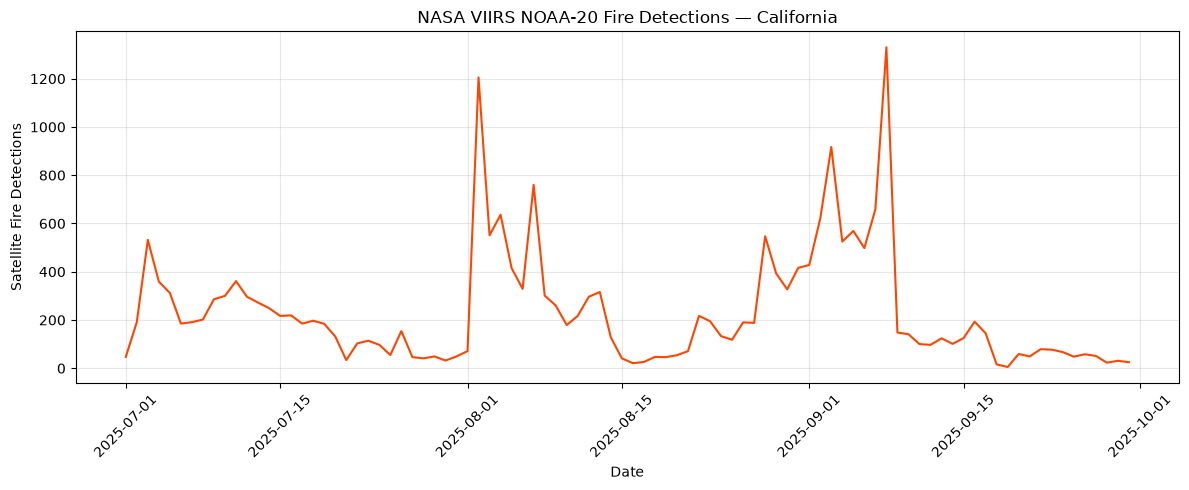

In [5]:

import matplotlib.pyplot as plt

# Convert date column
fires["acq_date"] = pd.to_datetime(
    fires["acq_date"]
)

# Count detections per day
daily_fires = (
    fires.groupby("acq_date")
    .size()
    .reset_index(name="fire_detections")
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_fires["acq_date"],
    daily_fires["fire_detections"],
    color="orangered"
)

plt.title(
    "NASA VIIRS NOAA-20 Fire Detections — California"
)
plt.xlabel("Date")
plt.ylabel("Satellite Fire Detections")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


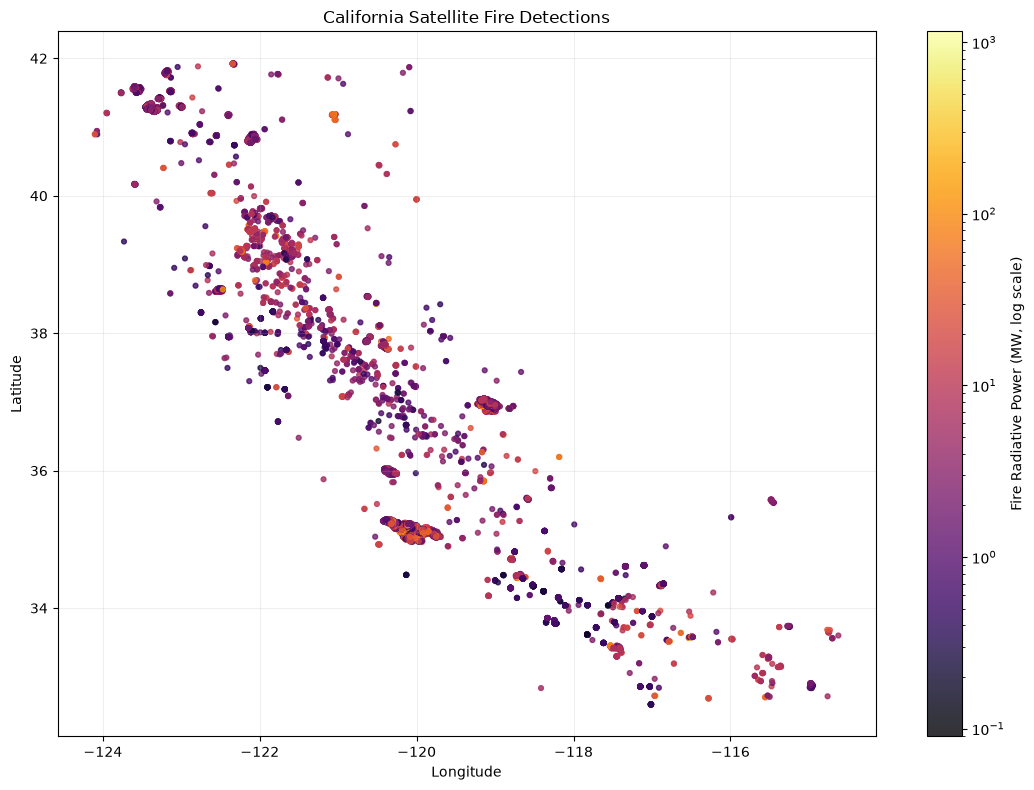

In [8]:

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

# Only include valid, positive FRP values
plot_data = fires[
    fires["frp"].notna() &
    (fires["frp"] > 0)
].copy()

plt.figure(figsize=(11, 8))

scatter = plt.scatter(
    plot_data["longitude"],
    plot_data["latitude"],
    c=plot_data["frp"],
    cmap="inferno",
    norm=LogNorm(
        vmin=plot_data["frp"].min(),
        vmax=plot_data["frp"].max()
    ),
    s=12,
    alpha=0.8
)

plt.colorbar(
    scatter,
    label="Fire Radiative Power (MW, log scale)"
)

plt.title("California Satellite Fire Detections")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [10]:

import pandas as pd
from pathlib import Path

# Work with a copy of the original observations
fires_clean = fires.copy()

# Standardize dates and numeric columns
fires_clean["acq_date"] = pd.to_datetime(
    fires_clean["acq_date"],
    errors="coerce"
)

numeric_cols = [
    "latitude", "longitude",
    "brightness", "bright_t31",
    "frp", "scan", "track"
]

for col in numeric_cols:
    fires_clean[col] = pd.to_numeric(
        fires_clean[col],
        errors="coerce"
    )

# Standardize confidence labels
confidence_labels = {
    "l": "low",
    "n": "nominal",
    "h": "high"
}

fires_clean["confidence_label"] = (
    fires_clean["confidence"].map(confidence_labels)
)

# Remove records missing essential fields
fires_clean = fires_clean.dropna(
    subset=[
        "latitude", "longitude",
        "acq_date", "frp"
    ]
)

# Validate geographic coordinates
fires_clean = fires_clean[
    fires_clean["latitude"].between(-90, 90)
    & fires_clean["longitude"].between(-180, 180)
    & (fires_clean["frp"] >= 0)
]

# Remove exact duplicates only
fires_clean = fires_clean.drop_duplicates()

print("Original detections:", len(fires))
print("Cleaned detections:", len(fires_clean))
print("Removed:", len(fires) - len(fires_clean))

display(fires_clean.head())


Original detections: 21694
Cleaned detections: 21694
Removed: 0


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type,confidence_label
0,34.62197,-117.10059,303.00,0.45,0.63,2025-07-01,846,N20,VIIRS,n,2,292.27,0.64,N,2,nominal
1,34.61035,-117.33772,316.90,0.47,0.64,2025-07-01,846,N20,VIIRS,n,2,292.73,1.76,N,2,nominal
2,34.60659,-117.34089,301.31,0.47,0.64,2025-07-01,846,N20,VIIRS,n,2,289.42,0.84,N,2,nominal
3,34.60629,-117.33533,303.55,0.47,0.64,2025-07-01,846,N20,VIIRS,n,2,291.19,0.84,N,2,nominal
4,34.43327,-118.64594,298.84,0.55,0.68,2025-07-01,846,N20,VIIRS,n,2,287.55,0.39,N,2,nominal


In [11]:

output_path = (
    project_dir / "data/processed/fires_cleaned.csv"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

fires_clean.to_csv(output_path, index=False)

print("Saved to:", output_path)


Saved to: /Users/sumanthkamath/Documents/VS Code /EcoSentinel/data/processed/fires_cleaned.csv


In [12]:

daily_summary = (
    fires_clean.groupby("acq_date")
    .agg(
        detections=("frp", "size"),
        total_frp=("frp", "sum"),
        mean_frp=("frp", "mean")
    )
    .reset_index()
)

display(daily_summary.head())

# Highest detection-count days
display(
    daily_summary.nlargest(5, "detections")
)

# Highest summed-FRP days
display(
    daily_summary.nlargest(5, "total_frp")
)


,acq_date,detections,total_frp,mean_frp
0,2025-07-01,47,324.57,6.905745
1,2025-07-02,191,17119.22,89.629424
2,2025-07-03,532,11978.21,22.515432
3,2025-07-04,359,4525.03,12.604540
4,2025-07-05,312,2527.45,8.100801


,acq_date,detections,total_frp,mean_frp
69,2025-09-08,1330,32024.82,24.078812
32,2025-08-02,1205,43973.63,36.492639
64,2025-09-03,917,9967.43,10.869607
37,2025-08-07,760,25558.14,33.629132
68,2025-09-07,659,11068.63,16.796100


,acq_date,detections,total_frp,mean_frp
32,2025-08-02,1205,43973.63,36.492639
69,2025-09-08,1330,32024.82,24.078812
37,2025-08-07,760,25558.14,33.629132
34,2025-08-04,636,24270.26,38.160786
38,2025-08-08,301,22879.93,76.013056


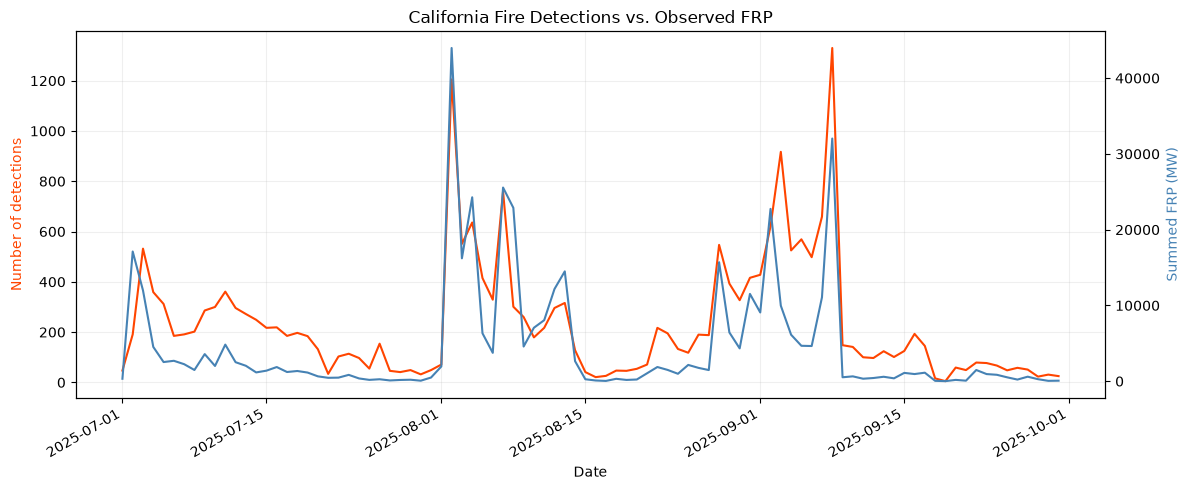

In [13]:

import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(12, 5))

# Daily fire detections
ax1.plot(
    daily_summary["acq_date"],
    daily_summary["detections"],
    color="orangered",
    label="Fire detections"
)

ax1.set_xlabel("Date")
ax1.set_ylabel("Number of detections", color="orangered")

# Daily summed FRP
ax2 = ax1.twinx()

ax2.plot(
    daily_summary["acq_date"],
    daily_summary["total_frp"],
    color="steelblue",
    label="Summed FRP"
)

ax2.set_ylabel("Summed FRP (MW)", color="steelblue")

plt.title("California Fire Detections vs. Observed FRP")
ax1.grid(alpha=0.2)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


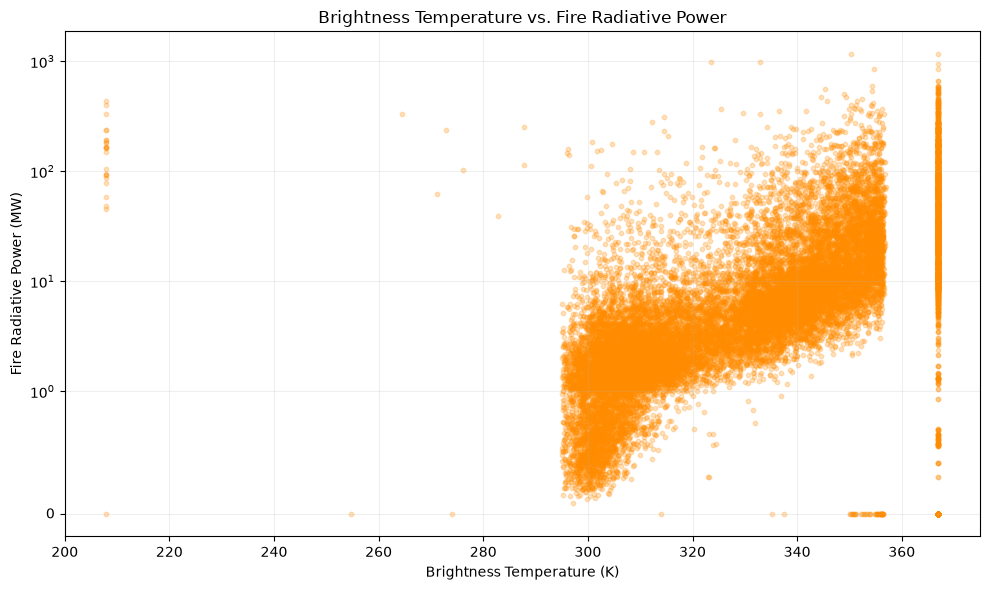

Spearman correlation: 0.761


In [14]:

import numpy as np
import matplotlib.pyplot as plt

# Keep valid observations for analysis
analysis_data = fires_clean.dropna(
    subset=["brightness", "frp"]
).copy()

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    analysis_data["brightness"],
    analysis_data["frp"],
    alpha=0.25,
    s=10,
    color="darkorange"
)

plt.xlabel("Brightness Temperature (K)")
plt.ylabel("Fire Radiative Power (MW)")
plt.title("Brightness Temperature vs. Fire Radiative Power")

# Log-like scale that can display zero FRP
plt.yscale("symlog", linthresh=1)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Calculate Spearman correlation
correlation = analysis_data[
    ["brightness", "frp"]
].corr(method="spearman").iloc[0, 1]

print("Spearman correlation:", round(correlation, 3))


In [15]:

# Save daily wildfire statistics
output_path = (
    project_dir / "data/processed/daily_fire_summary.csv"
)

daily_summary.to_csv(output_path, index=False)

print("Daily wildfire summary saved successfully!")
print(output_path)


Daily wildfire summary saved successfully!
/Users/sumanthkamath/Documents/VS Code /EcoSentinel/data/processed/daily_fire_summary.csv


In [ ]:
c